In [11]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

Predictions:
- Circuit A (X): always 1
- Circuit B (X, X): always 0
- Circuit C (H): about 50% 0 and 50% 1, changes each run

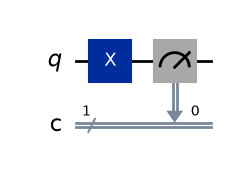

In [12]:
qc_a = QuantumCircuit(1, 1)
qc_a.x(0)
qc_a.measure(0, 0)
qc_a.draw("mpl")

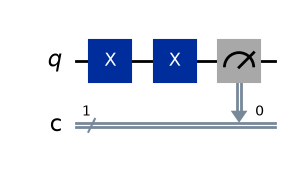

In [13]:
qc_b = QuantumCircuit(1, 1)
qc_b.x(0)
qc_b.x(0)
qc_b.measure(0, 0)
qc_b.draw("mpl")

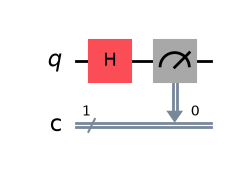

In [14]:
qc_c = QuantumCircuit(1, 1)
qc_c.h(0)
qc_c.measure(0, 0)
qc_c.draw("mpl")

In [15]:
sim = AerSimulator()
counts_a = sim.run(qc_a, shots=100).result().get_counts()
counts_b = sim.run(qc_b, shots=100).result().get_counts()
counts_c = sim.run(qc_c, shots=100).result().get_counts()
print("A:", counts_a)
print("B:", counts_b)
print("C:", counts_c)

A: {'1': 100}
B: {'0': 100}
C: {'1': 48, '0': 52}


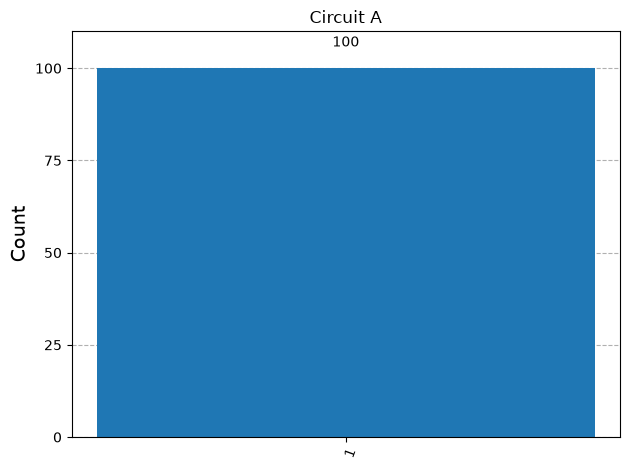

In [16]:
plot_histogram(counts_a, title="Circuit A")

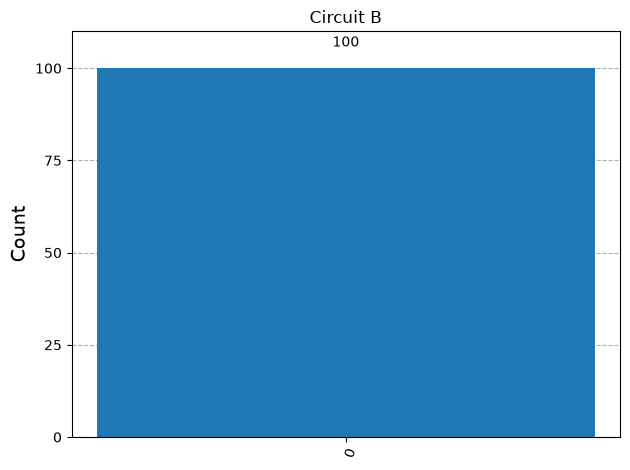

In [17]:
plot_histogram(counts_b, title="Circuit B")

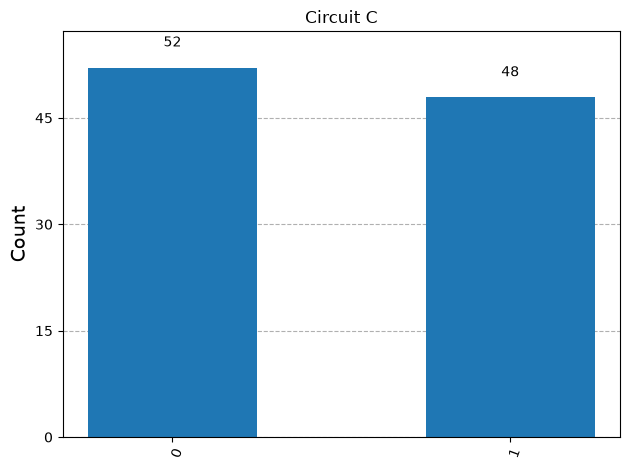

In [18]:
plot_histogram(counts_c, title="Circuit C")

## Comparison: Prediction vs Actual

- **Circuit A (X):** Predicted always `1`. Result: `{'1': 100}`. Matches, because the X gate flips |0⟩ to |1⟩.
- **Circuit B (X, X):** Predicted always `0`. Result: `{'0': 100}`. Matches, because two X gates cancel out and the qubit returns to |0⟩.
- **Circuit C (H):** Predicted about 50% `0` and 50% `1`. Result: `{'0': 52, '1': 48}`. Matches, with a small deviation from exactly 50/50 because only 100 shots were used.

**Will Circuit C always give the same result?** No. The H gate puts the qubit in superposition, so each measurement is random. Re-running gives slightly different counts, unlike A and B, which are deterministic.